# Анализ тональности: классические модели

Классификация комментариев на три класса: NEGATIVE, NEUTRAL, POSITIVE. Метки были автоматически получены из RuBERT и не являются ручной разметкой.

## Данные

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

Path('results').mkdir(exist_ok=True)
df = pd.read_csv(Path.home() / 'ML_private_datasets' / 'nlp' / 'my_comments_labeled_corrected.csv')
df = df[['comment_text_clean', 'sentiment_label']].dropna()
df = df[df['comment_text_clean'].str.strip().ne('')].drop_duplicates('comment_text_clean')

X = df['comment_text_clean']
y = df['sentiment_label']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.25, stratify=y_train, random_state=42)
print('Train:', len(X_train), '| Validation:', len(X_val), '| Test:', len(X_test))

Train: 1983 | Validation: 661 | Test: 662


## TF-IDF и модели

In [2]:
tfidf = TfidfVectorizer(max_features=12000, min_df=2, ngram_range=(1, 2), sublinear_tf=True)
train_vectors = tfidf.fit_transform(X_train)
val_vectors = tfidf.transform(X_val)

models = {
    'Most frequent': DummyClassifier(strategy='most_frequent'),
    'Naive Bayes': MultinomialNB(alpha=0.7),
    'Linear SVM': LinearSVC(class_weight='balanced', random_state=42),
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
}

scores = []
for name, model in models.items():
    model.fit(train_vectors, y_train)
    pred = model.predict(val_vectors)
    scores.append([name, accuracy_score(y_val, pred), f1_score(y_val, pred, average='macro')])

results = pd.DataFrame(scores, columns=['model', 'validation_accuracy', 'validation_macro_f1'])
results = results.sort_values('validation_macro_f1', ascending=False)
display(results.round(3))
results.to_csv('results/validation_classical.csv', index=False)

,model,validation_accuracy,validation_macro_f1
3,Logistic Regression,0.628,0.588
2,Linear SVM,0.640,0.552
1,Naive Bayes,0.648,0.391
0,Most frequent,0.602,0.251


## Тест и матрица ошибок

Logistic Regression: Accuracy = 0.636, Macro F1 = 0.596
              precision    recall  f1-score   support

    NEGATIVE       0.41      0.50      0.45       142
     NEUTRAL       0.75      0.69      0.72       399
    POSITIVE       0.62      0.62      0.62       121

    accuracy                           0.64       662
   macro avg       0.59      0.60      0.60       662
weighted avg       0.65      0.64      0.64       662



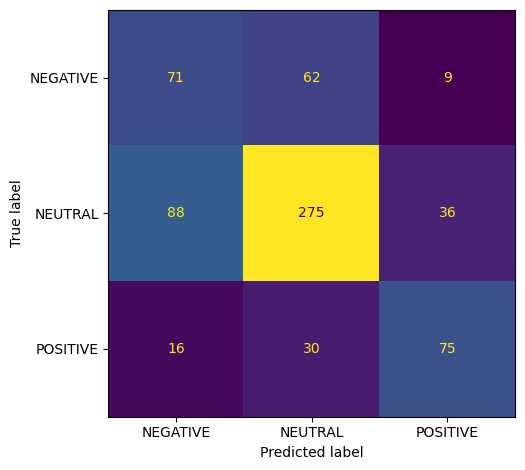

In [3]:
best_name = results.iloc[0]['model']
model = models[best_name]
test_vectors = tfidf.transform(X_test)
pred = model.predict(test_vectors)

accuracy = accuracy_score(y_test, pred)
macro_f1 = f1_score(y_test, pred, average='macro')
print(f'{best_name}: Accuracy = {accuracy:.3f}, Macro F1 = {macro_f1:.3f}')
print(classification_report(y_test, pred, zero_division=0))

pd.DataFrame([{'model': best_name, 'test_accuracy': accuracy, 'test_macro_f1': macro_f1}]).to_csv('results/test_classical.csv', index=False)
ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=['NEGATIVE','NEUTRAL','POSITIVE'], colorbar=False)
plt.tight_layout()
plt.savefig('results/confusion_matrix_classical.png', dpi=150)
plt.show()

**Ограничение:** тестовые метрики показывают совпадение с автоматическими метками RuBERT, а не точность по человеческой разметке.